In [1]:
import pandas as pd
df = pd.read_csv("state_data.csv")
# there are 52 rows and 4 columns
df

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California
5,CO,39.550051,-105.782067,Colorado
6,CT,41.603221,-73.087749,Connecticut
7,DC,38.905985,-77.033418,District of Columbia
8,DE,38.910832,-75.527670,Delaware
9,FL,27.664827,-81.515754,Florida


In [2]:
df.shape

(52, 4)

In [3]:
df.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [4]:
df.tail()

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [5]:
'''the first column is the state, then the geographical position using longitude and latitude, and finally the states name fully spelled out the first state is Alaska and the last is Wyoming there are 52 total entries and theres more than 50 because Puerto Rico and Washington DC are listed'''

'the first column is the state, then the geographical position using longitude and latitude, and finally the states name fully spelled out the first state is Alaska and the last is Wyoming there are 52 total entries and theres more than 50 because Puerto Rico and Washington DC are listed'

In [6]:
median_latitude = df['latitude'].median()
print(median_latitude)

39.4355155


In [7]:
median_longitude = df['longitude'].median()
print(median_longitude)

-89.093198


In [8]:
df['lat_dist_to_median'] = (df['latitude'] - median_latitude).abs()
df['lon_dist_to_median'] = (df['longitude'] - median_longitude).abs()
df

,state,latitude,longitude,name,lat_dist_to_median,lon_dist_to_median
0,AK,63.588753,-154.493062,Alaska,24.153237,65.399864
1,AL,32.318231,-86.902298,Alabama,7.117285,2.190900
2,AR,35.201050,-91.831833,Arkansas,4.234465,2.738635
3,AZ,34.048928,-111.093731,Arizona,5.386588,22.000533
4,CA,36.778261,-119.417932,California,2.657255,30.324734
5,CO,39.550051,-105.782067,Colorado,0.114536,16.688869
6,CT,41.603221,-73.087749,Connecticut,2.167705,16.005449
7,DC,38.905985,-77.033418,District of Columbia,0.529530,12.059780
8,DE,38.910832,-75.527670,Delaware,0.524684,13.565528
9,FL,27.664827,-81.515754,Florida,11.770689,7.577444


In [9]:
df.shape
#there are still 52 rows but now 6 columns since I added 2

(52, 6)

In [10]:
idx_closest_lat = df['lat_dist_to_median'].idxmin()
state_closest_lat = df.loc[idx_closest_lat, 'name']
dist_closest_lat = df.loc[idx_closest_lat, 'lat_dist_to_median']

idx_farthest_lat = df['lat_dist_to_median'].idxmax()
state_farthest_lat = df.loc[idx_farthest_lat, 'name']
dist_farthest_lat = df.loc[idx_farthest_lat, 'lat_dist_to_median']

idx_closest_lon = df['lon_dist_to_median'].idxmin()
state_closest_lon = df.loc[idx_closest_lon, 'name']
dist_closest_lon = df.loc[idx_closest_lon, 'lon_dist_to_median']

idx_farthest_lon = df['lon_dist_to_median'].idxmax()
state_farthest_lon = df.loc[idx_farthest_lon, 'name']
dist_farthest_lon = df.loc[idx_farthest_lon, 'lon_dist_to_median']

print(f"State closest to the median latitude: {state_closest_lat} by {dist_closest_lat:.2f}")
print(f"State farthest from the median latitude: {state_farthest_lat} by {dist_farthest_lat:.2f}")
print(f"State closest to the median longitude: {state_closest_lon} by {dist_closest_lon:.2f}")
print(f"State farthest from the median longitude: {state_farthest_lon} by {dist_farthest_lon:.2f}")

State closest to the median latitude: Colorado by 0.11
State farthest from the median latitude: Alaska by 24.15
State closest to the median longitude: Illinois by 0.31
State farthest from the median longitude: Hawaii by 66.57


In [28]:
far_states = df.query("latitude > 47.0")
print(far_states)
#this will show the states only with latitudes greater than 47
#I found this in the user guide in the pandas website

   state   latitude   longitude          name  lat_dist_to_median  \
0     AK  63.588753 -154.493062        Alaska           24.153237   
28    ND  47.551493 -101.002012  North Dakota            8.115977   
48    WA  47.751074 -120.740139    Washington            8.315559   

    lon_dist_to_median  
0            65.399864  
28           11.908814  
48           31.646941  


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
df = sns.load_dataset("titanic")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [36]:
print("already done by seaborn are the first couple questions, the rows are each passenger of the titanic and the columns detail their personal info liek age, sex, class, etc.")

already done by seaborn are the first couple questions, the rows are each passenger of the titanic and the columns detail their personal info liek age, sex, class, etc.


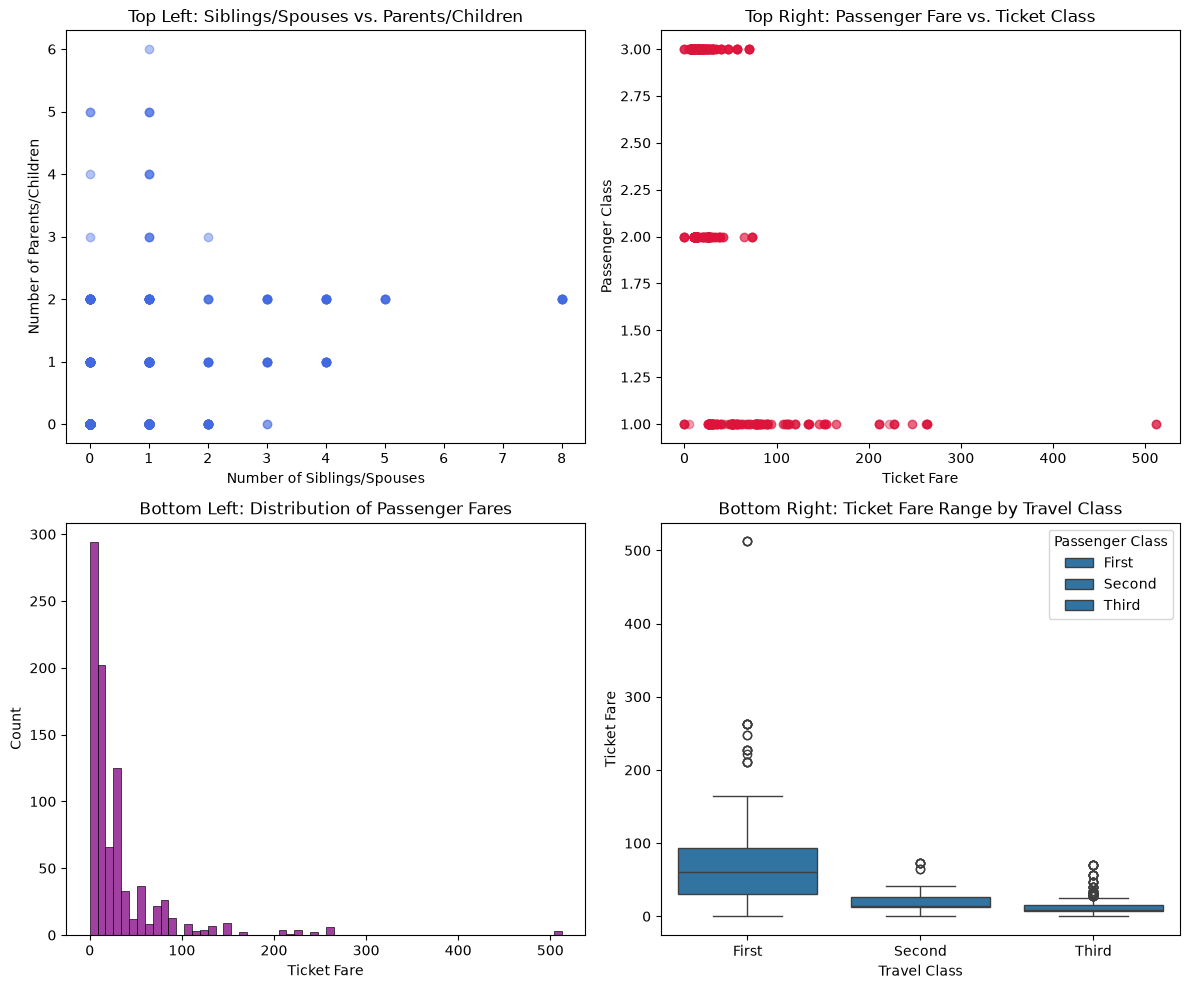

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(df["sibsp"], df["parch"], color="royalblue", alpha=0.4)
axes[0, 0].set_title("Top Left: Siblings/Spouses vs. Parents/Children")
axes[0, 0].set_xlabel("Number of Siblings/Spouses")
axes[0, 0].set_ylabel("Number of Parents/Children")

axes[0, 1].scatter(df["fare"], df["pclass"], color="crimson", alpha=0.4)
axes[0, 1].set_title("Top Right: Passenger Fare vs. Ticket Class")
axes[0, 1].set_xlabel("Ticket Fare")
axes[0, 1].set_ylabel("Passenger Class")

sns.histplot(data=df, x="fare", ax=axes[1, 0], color="purple")
axes[1, 0].set_title("Bottom Left: Distribution of Passenger Fares")
axes[1, 0].set_xlabel("Ticket Fare")

sns.boxplot(data=df, x="class", y="fare", ax=axes[1, 1])
axes[1, 1].set_title("Bottom Right: Ticket Fare Range by Travel Class")
axes[1, 1].set_xlabel("Travel Class")
axes[1, 1].set_ylabel("Ticket Fare")
axes[1, 1].legend(title="Passenger Class", labels=["First", "Second", "Third"])
plt.tight_layout()
plt.show()

In [45]:
print("these subplots represent the same things their titles say, in the ticket fare chart the most common ones were very cheap wehre only some paye over 200, today wed be lucky to go on a cruise for less than 200")

these subplots represent the same things their titles say, in the ticket fare chart the most common ones were very cheap wehre only some paye over 200, today wed be lucky to go on a cruise for less than 200
